# 02 – Final Model Comparison

This notebook consolidates the held-out test metrics from the five required classifiers, validates the comparison table, generates the required metric visualisations, and documents the overall winner.

**Important:** This notebook does not retrain models or tune against the test set. It reads the test metrics already produced by the five model notebooks.

In [1]:
from pathlib import Path
import sys
import subprocess
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / 'results' / 'model_comparison.csv').exists():
    ROOT = ROOT.parent
if not (ROOT / 'results' / 'model_comparison.csv').exists():
    raise FileNotFoundError('Run this notebook from the project root or notebooks/ folder.')

comparison_path = ROOT / 'results' / 'model_comparison.csv'
comparison = pd.read_csv(comparison_path)
metrics = ['Accuracy', 'AUC', 'Precision', 'Recall', 'F1', 'MCC']
required_columns = ['Model', *metrics]
assert set(required_columns).issubset(comparison.columns)
assert len(comparison) == 5 and comparison['Model'].nunique() == 5
assert comparison[metrics].notna().all().all()
assert comparison[metrics].apply(lambda col: col.between(0, 1).all()).all()

display(comparison.style.format({metric: '{:.4f}' for metric in metrics}))

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.7734,0.8657,0.5595,0.8254,0.6669,0.5266
1,Decision Tree,0.7656,0.8756,0.5463,0.8689,0.6708,0.5358
2,K-Nearest Neighbors,0.8177,0.8709,0.6869,0.6191,0.6513,0.5297
3,Gaussian Naive Bayes,0.7165,0.7697,0.4890,0.6957,0.5743,0.3844
4,Random Forest,0.7793,0.8887,0.5659,0.8472,0.6786,0.5451


## Generate six required metric graphs

The following script creates one six-panel comparison graphic and six standalone metric graphs under `results/visualizations/`. All values are read from `results/model_comparison.csv`.

Validated 5 models and 6 metrics.
Saved consolidated chart: /mnt/data/ML-Assignment-2-rf-work/ML-Assignment-2/results/visualizations/all_models_metrics_comparison.png
Saved six individual metric charts under: /mnt/data/ML-Assignment-2-rf-work/ML-Assignment-2/results/visualizations


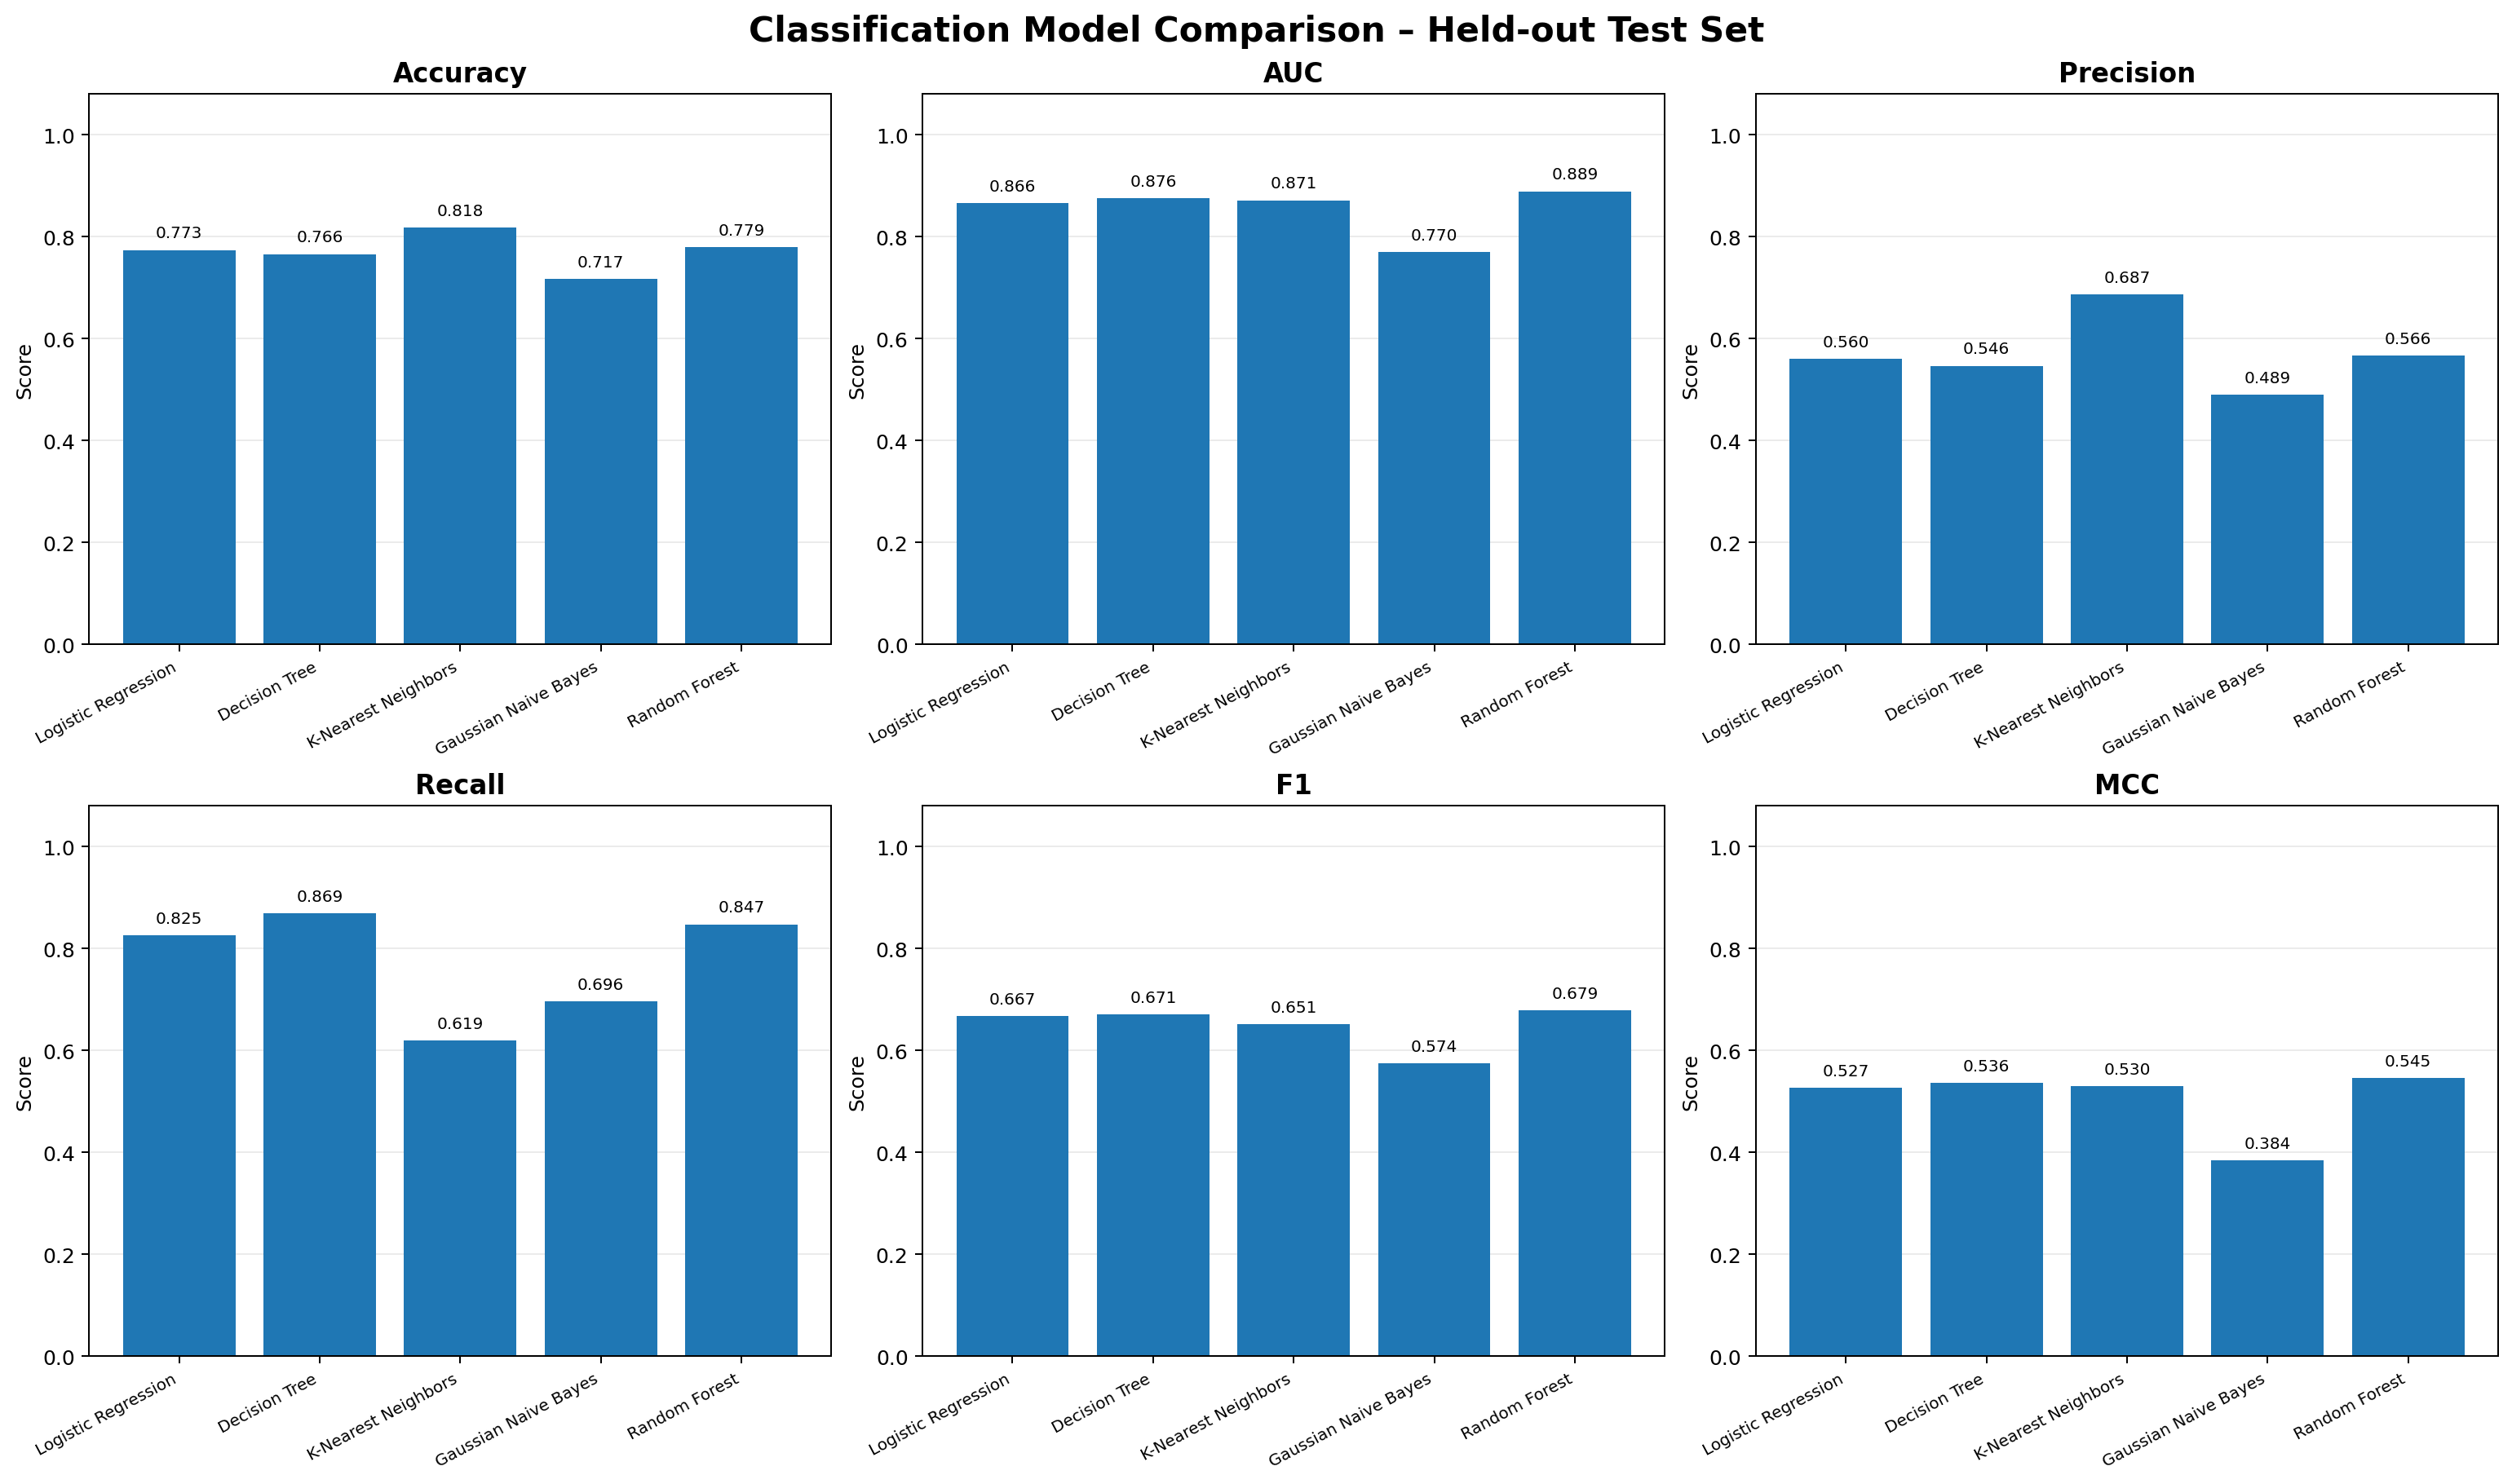

In [2]:
script_path = ROOT / 'scripts' / 'generate_model_comparison.py'
subprocess.run([sys.executable, str(script_path)], cwd=ROOT, check=True)
all_metrics_chart = ROOT / 'results' / 'visualizations' / 'all_models_metrics_comparison.png'
display(Image(filename=str(all_metrics_chart)))

## Model-by-model observations

| Model | Observation about test performance |
|---|---|
| Logistic Regression | Provides a useful linear baseline with 82.54% recall and 86.57% AUC. Its 55.95% precision indicates a meaningful number of false-positive cancellation predictions. |
| Decision Tree | Has the highest recall (86.89%), so it catches the largest share of cancelled bookings. It has lower accuracy and precision than KNN and lower AUC, F1 and MCC than Random Forest. |
| K-Nearest Neighbors | Has the highest accuracy (81.77%) and precision (68.69%), but the lowest recall (61.91%). It is more conservative about predicting cancellations and misses more actual cancellations. Its result is for the full preprocessing + SVD + KNN pipeline. |
| Gaussian Naive Bayes | Has the lowest accuracy, AUC, precision, F1 and MCC of the five models. Its recall (69.57%) is higher than KNN's but lower than the other three models. Its threshold was selected using a validation slice from training data, not the held-out test data. |
| Random Forest | Achieves the highest AUC (88.87%), F1 (67.86%) and MCC (54.51%). Its recall (84.72%) is also high, though slightly below the Decision Tree. Accuracy and precision are below KNN. |

## Overall winner: Random Forest

For this dataset, **Random Forest is the overall winner** when the goal is balanced cancellation detection rather than maximising accuracy alone. It leads on AUC, F1 and MCC, while retaining high recall. AUC measures ranking/discrimination across thresholds; F1 balances precision and recall at the selected threshold; and MCC provides a balanced summary of the confusion matrix.

This is not a claim that Random Forest is best for every operational objective. KNN is preferable if the priority is the highest observed accuracy and precision, while Decision Tree is preferable if the priority is maximising recall and catching as many cancellations as possible. The selected winner reflects the balanced-metric priority for this assignment.

**Caveat:** These are results from one stratified 80:20 hold-out split with `random_state=42`. A different split or external dataset may produce a different ranking.

## Reproducibility notes

- All five model notebooks use the same `data/train_data.csv` and `test_data.csv` partitions.
- The test set is held out from model fitting and hyperparameter/threshold selection.
- Preprocessing transformations are fitted on training data only.
- Run this notebook after all five model notebooks to refresh the charts from the current `model_comparison.csv`.